Note- These materials were developed by Dr. Sandeep Singh Sengar for teaching purposes at Cardiff Metropolitan University. They may be used by only enrolled students under him for personal study and should not be reproduced, distributed, or shared publicly without permission from the author.

#Data Preprocessing (Superstore Dataset)
Covers: Missing Values, Standardization, Normalization, and Binning


# Part 1: Load and Inspect Data


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


df = pd.read_csv("superstore.csv", encoding='latin1')

# Show basic info
print("Dataset loaded successfully!\n")
print("Shape of dataset:", df.shape)

Dataset loaded successfully!

Shape of dataset: (9994, 21)


In [3]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [4]:
print("\nColumn information:")
df.info()


Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   

In [5]:
# Check missing values
print("\nMissing values")
print(df.isna().sum())


Missing values
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64


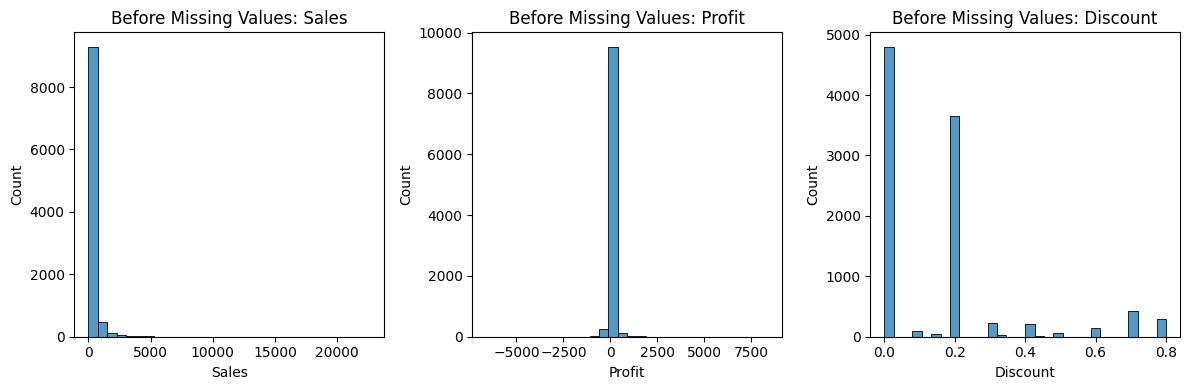

In [6]:
# Plot histograms of numeric columns before missing values
numeric_cols = ['Sales', 'Profit', 'Discount']
plt.figure(figsize=(12, 4))
for i, col in enumerate(numeric_cols, 1):
    plt.subplot(1, 3, i)
    sns.histplot(df[col], kde=False, bins=30)
    plt.title(f"Before Missing Values: {col}")
plt.tight_layout()
plt.show()

#Part 2 – Create Artificial Missing Values

We’ll simulate real-world data problems:

Large number of missing values in "Postal Code" (we’ll drop it later).

Moderate number in "Profit".

Small number in "Region" and "Category".

In [7]:
# Large number of missing values (around 60%)
np.random.seed(42)
large_missing_idx = np.random.choice(df.index, size=int(0.6 * len(df)), replace=False)
df.loc[large_missing_idx, 'Postal Code'] = np.nan




In [8]:
# Moderate number (around 20%)
medium_missing_idx = np.random.choice(df.index, size=int(0.2 * len(df)), replace=False)
df.loc[medium_missing_idx, 'Profit'] = np.nan



In [9]:
# Small number (around 5%)
small_missing_idx = np.random.choice(df.index, size=int(0.05 * len(df)), replace=False)
df.loc[small_missing_idx, 'Region'] = np.nan
df.loc[small_missing_idx, 'Category'] = np.nan

print("\n Artificial missing values created.")
print(df.isna().sum())


 Artificial missing values created.
Row ID              0
Order ID            0
Order Date          0
Ship Date           0
Ship Mode           0
Customer ID         0
Customer Name       0
Segment             0
Country             0
City                0
State               0
Postal Code      5996
Region            499
Product ID          0
Category          499
Sub-Category        0
Product Name        0
Sales               0
Quantity            0
Discount            0
Profit           1998
dtype: int64


Histogram After Introducing Missing Values

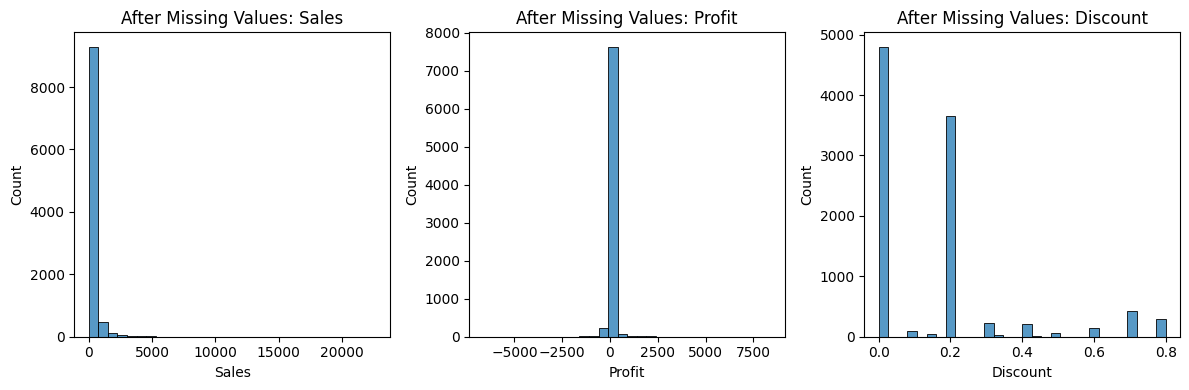

In [10]:
plt.figure(figsize=(12, 4))
for i, col in enumerate(numeric_cols, 1):
    plt.subplot(1, 3, i)
    sns.histplot(df[col], kde=False, bins=30)
    plt.title(f"After Missing Values: {col}")
plt.tight_layout()
plt.show()


Observation

Fewer data points → some histogram bars are shorter or missing entirely.

Profit now has gaps — this visually reinforces why missing value treatment is important.

#Part 3 – Handle Missing Values

In [11]:
from sklearn.impute import SimpleImputer

# Drop columns with too many missing values (>50%)
missing_percent = df.isna().mean() * 100
cols_to_drop = missing_percent[missing_percent > 50].index
df.drop(columns=cols_to_drop, inplace=True)

print(f"\nDropped columns with >50% missing values: {list(cols_to_drop)}")




Dropped columns with >50% missing values: ['Postal Code']


In [12]:
# For numeric column 'Profit' (moderate missing) → fill with median
median_imputer = SimpleImputer(strategy='median')
df['Profit'] = median_imputer.fit_transform(df[['Profit']]).ravel()




In [13]:
# For categorical 'Region' (few missing) → fill with mode (most frequent)
mode_imputer = SimpleImputer(strategy='most_frequent')
df['Region'] = mode_imputer.fit_transform(df[['Region']]).ravel()



In [14]:
# For categorical 'Category' (few missing) → fill with constant value
constant_imputer = SimpleImputer(strategy='constant', fill_value='Unknown') #In this case, the constant is the string 'Unknown'.
df['Category'] = constant_imputer.fit_transform(df[['Category']]).ravel()

# Verify results
print("\n Missing values after cleaning:")
print(df.isna().sum())


 Missing values after cleaning:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64


| Column          | Missing % | Type        | Strategy                 | Logic                                            |
| --------------- | --------- | ----------- | ------------------------ | ------------------------------------------------ |
| **Postal Code** | ~60%      | Numeric     | **Drop**                 | More than half missing → imputation unreliable   |
| **Profit**      | ~20%      | Numeric     | **Median**               | Median is robust to outliers and skew            |
| **Region**      | ~5%       | Categorical | **Mode**                 | Replace with most frequent value                 |
| **Category**    | ~5%       | Categorical | **Constant ('Unknown')** | Keeps transparency for originally missing values |


Visualize Histograms After Imputation

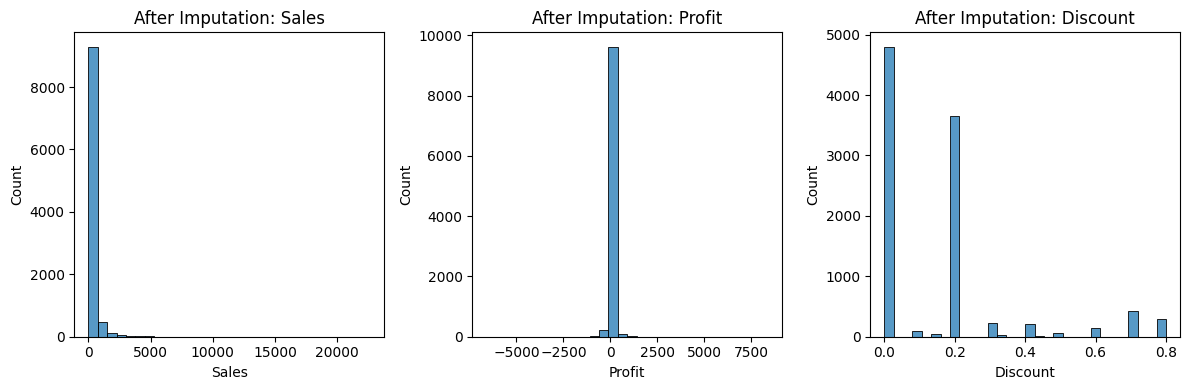

In [15]:
plt.figure(figsize=(12, 4))
for i, col in enumerate(numeric_cols, 1):
    plt.subplot(1, 3, i)
    sns.histplot(df[col], kde=False, bins=30)
    plt.title(f"After Imputation: {col}")
plt.tight_layout()
plt.show()


Observation

The histograms are now restored — all missing bars are filled in.

This shows how imputation brings completeness to the dataset.

#Part 4 – Standardization and Normalization

Standardization is a technique used to scale features so that they have a mean of 0 and a standard deviation of 1. It is particularly useful when the features of your data have different units or magnitudes.

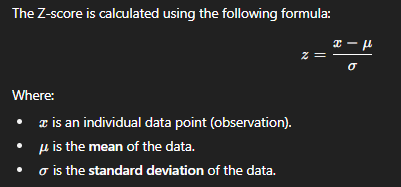

In [16]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# Choose numeric columns
numeric_cols = ['Sales', 'Discount', 'Profit']

# Standardization (mean = 0, std = 1)
std_scaler = StandardScaler()
df[[col + '_std' for col in numeric_cols]] = std_scaler.fit_transform(df[numeric_cols])




Normalization, also known as Min-Max scaling, is a technique used to scale the features of a dataset to a specific range, usually between 0 and 1. This is especially useful when features have different units or magnitudes and you want to transform them into a common scale, preserving the relationships between the data points.

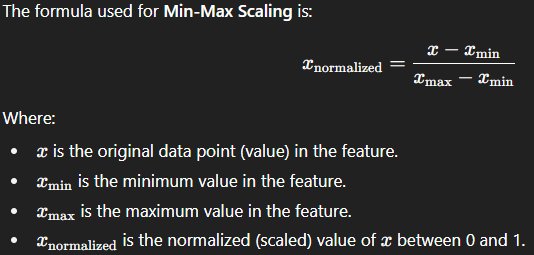

In [17]:
# Normalization (0–1 scale)
mm_scaler = MinMaxScaler()
df[[col + '_norm' for col in numeric_cols]] = mm_scaler.fit_transform(df[numeric_cols])


In [18]:

print("\n Scaling completed successfully.")
print(df[[col + '_std' for col in numeric_cols] + [col + '_norm' for col in numeric_cols]].describe())


 Scaling completed successfully.
          Sales_std  Discount_std    Profit_std   Sales_norm  Discount_norm  \
count  9.994000e+03  9.994000e+03  9.994000e+03  9994.000000    9994.000000   
mean  -4.550204e-17  7.251887e-17  3.554847e-19     0.010134       0.195253   
std    1.000050e+00  1.000050e+00  1.000050e+00     0.027531       0.258065   
min   -3.681144e-01 -7.566435e-01 -3.142270e+01     0.000000       0.000000   
25%   -3.410996e-01 -7.566435e-01 -1.011987e-01     0.000744       0.000000   
50%   -2.813929e-01  2.121533e-01 -7.540970e-02     0.002387       0.250000   
75%   -3.196013e-02  2.121533e-01 -1.743630e-02     0.009254       0.250000   
max    3.595655e+01  3.118544e+00  3.972639e+01     1.000000       1.000000   

       Profit_norm  
count  9994.000000  
mean      0.441646  
std       0.014056  
min       0.000000  
25%       0.440223  
50%       0.440586  
75%       0.441401  
max       1.000000  


| Method              | Formula                                 | Range        | Use Case                                         |
| ------------------- | --------------------------------------- | ------------ | ------------------------------------------------ |
| **Standardization** | ( z = (x - μ) / σ )                     | Mean=0, SD=1 | Used when data has outliers or for ML algorithms |
| **Normalization**   | ( (x - x_{min}) / (x_{max} - x_{min}) ) | 0–1          | Used for visualization or neural networks        |


#Part 5 – Data Binning (Discretization)

Data Binning is a technique used to convert continuous data into discrete intervals or bins. This is useful when you want to simplify your data, reduce noise, or convert continuous variables into categorical variables for easier analysis or modeling.

In [19]:
# Profit-based binning using business logic
profit_bins = [-1000, 0, 100, 500, 2000, 5000]
profit_labels = ['Loss', 'Low Profit', 'Medium Profit', 'High Profit', 'Very High Profit']
df['Profit_bin'] = pd.cut(df['Profit'], bins=profit_bins, labels=profit_labels, include_lowest=True) #The lowest interval (first bin) will include its leftmost value.




In [20]:
print("\nProfit bins distribution:")
print(df['Profit_bin'].value_counts())


Profit bins distribution:
Profit_bin
Low Profit          7773
Loss                1505
Medium Profit        606
High Profit           79
Very High Profit      11
Name: count, dtype: int64


In [21]:
# Sales quartile bins
df['Sales_bin'] = pd.qcut(df['Sales'], 4, labels=['Low_Sales','MidLow_Sales','MidHigh_Sales','High_Sales'])

In [22]:
print("\nSales bins distribution:")
print(df['Sales_bin'].value_counts())


Sales bins distribution:
Sales_bin
Low_Sales        2501
MidHigh_Sales    2499
High_Sales       2498
MidLow_Sales     2496
Name: count, dtype: int64


Binning groups numeric data into categories.

pd.cut() → fixed ranges (business rules).

pd.qcut() → quartiles (equal number of samples per bin).

Example: “Low Profit” vs “High Profit” helps business analysts categorize customers or products.

#Part 6 – Verify Final Data and Save

In [23]:
print("\n Final dataset info:")
df.info()


 Final dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 28 columns):
 #   Column         Non-Null Count  Dtype   
---  ------         --------------  -----   
 0   Row ID         9994 non-null   int64   
 1   Order ID       9994 non-null   object  
 2   Order Date     9994 non-null   object  
 3   Ship Date      9994 non-null   object  
 4   Ship Mode      9994 non-null   object  
 5   Customer ID    9994 non-null   object  
 6   Customer Name  9994 non-null   object  
 7   Segment        9994 non-null   object  
 8   Country        9994 non-null   object  
 9   City           9994 non-null   object  
 10  State          9994 non-null   object  
 11  Region         9994 non-null   object  
 12  Product ID     9994 non-null   object  
 13  Category       9994 non-null   object  
 14  Sub-Category   9994 non-null   object  
 15  Product Name   9994 non-null   object  
 16  Sales          9994 non-null   float64 
 17  Quantity   

In [24]:
print("\nMissing values after full preprocessing:")
print(df.isna().sum())



Missing values after full preprocessing:
Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
Sales_std         0
Discount_std      0
Profit_std        0
Sales_norm        0
Discount_norm     0
Profit_norm       0
Profit_bin       20
Sales_bin         0
dtype: int64


Why are 20 values missing in Profit_bin?

When you run the pd.cut() function, Pandas will assign NaN to the values that do not fall within any of the specified bins. This typically happens if the Profit values in your dataset are outside the range of the bins you defined.

In [25]:

# Save cleaned dataset
df.to_csv("superstore_preprocessed.csv", index=False)
print("\n Preprocessed dataset saved as 'superstore_preprocessed.csv'")


 Preprocessed dataset saved as 'superstore_preprocessed.csv'
